Bibliotecas

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

In [4]:
TARGET = "play_type"
CLASSES = ["run", "pass"]

MAX_CATEGORIAS = 12

df = pd.read_csv("../Data/DadosFiltradosParaAnaliseExploratoria.csv")
df[TARGET] = df[TARGET].str.lower().str.strip()
df = df[df[TARGET].isin(CLASSES)].copy()

Grafico de distribuição Pass/Run

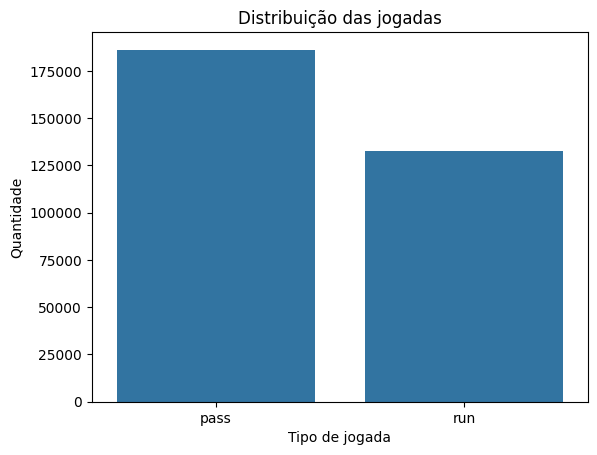

In [5]:
sns.countplot(data=df, x="play_type")

plt.title("Distribuição das jogadas")
plt.xlabel("Tipo de jogada")
plt.ylabel("Quantidade")
plt.show()

In [6]:
vetor_percentuais = df["play_type"].value_counts(normalize=True) * 100
print("proporção de cada tipo de jogada em %:")
print("pass:", vetor_percentuais.iloc[0])
print("run:", vetor_percentuais.iloc[1])

proporção de cada tipo de jogada em %:
pass: 58.41771496527984
run: 41.58228503472015


Categorias das Variaveis

In [7]:
NUMERICAS = [
    "ydstogo",
    "scorediff",
    "yardline_100"
]

CATEGORICAS_ORDINAIS = [
    "down",
    "qtr"
]

CATEGORICAS_BINARIAS = [
    "home",
    "shotgun",
    "nohuddle",
    "goaltogo",
    "yardline90"
]

CATEGORICAS_NOMINAIS = [
    "posteam"
]

Função para barras normalizadas

In [8]:
def grafico_barra_normalizada(df, variavel):
    tabela = pd.crosstab(
        df[variavel],
        df[TARGET],
        normalize="index"
    ).mul(100)

    tabela = tabela.reindex(columns=CLASSES, fill_value=0)

    ax = tabela.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5),
        color=["#4C72B0", "#DD8452"]
    )

    plt.title(f"Tipo de jogada por {variavel}")
    plt.xlabel(variavel)
    plt.ylabel("Percentual (%)")
    plt.ylim(0, 100)
    plt.legend(title="Tipo de jogada")
    plt.tight_layout()
    plt.show()

Barras normalizadas para down, qrt, shotgun, nohuddle, goaltogo, yardline90 e home.

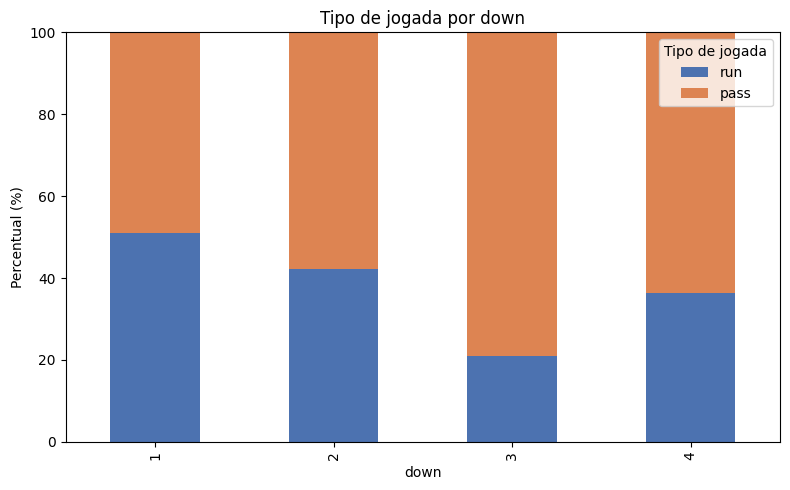

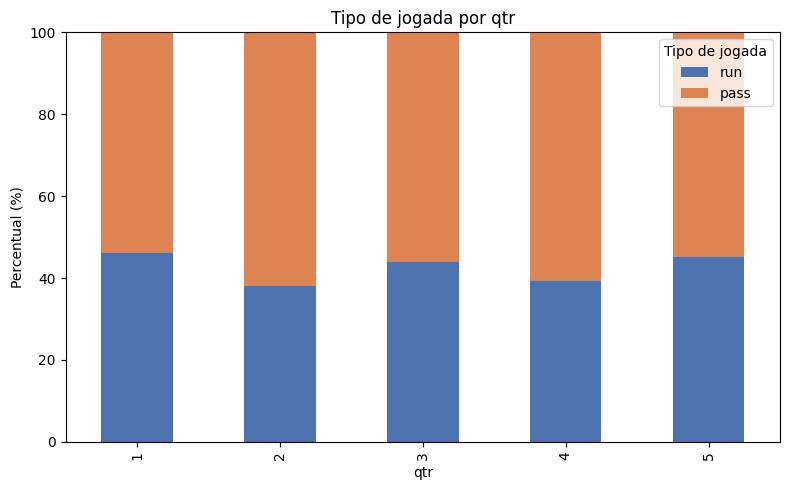

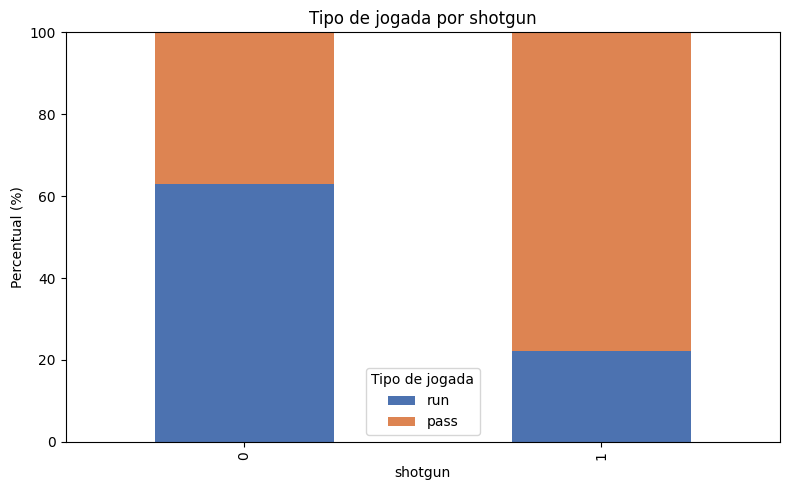

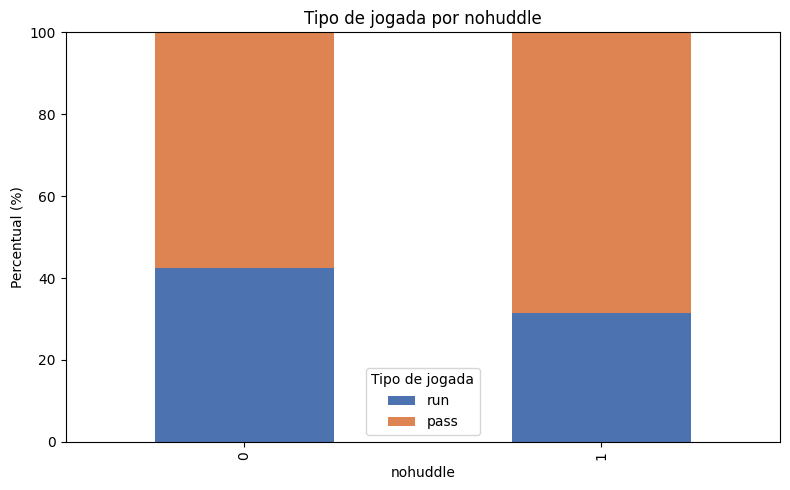

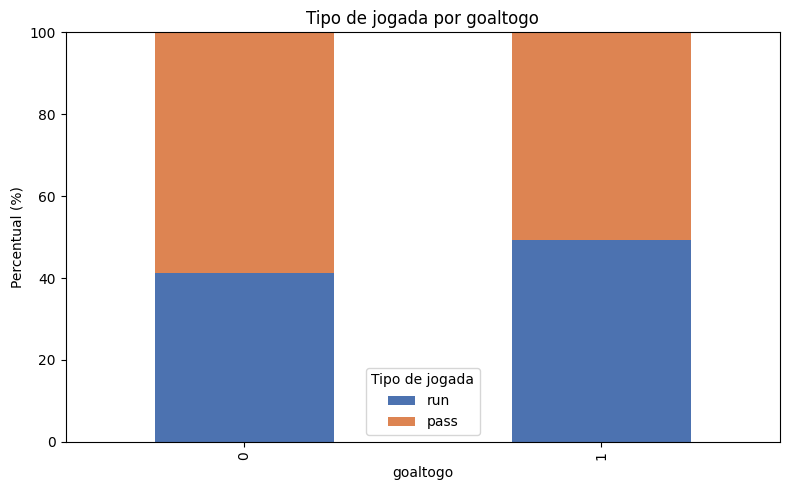

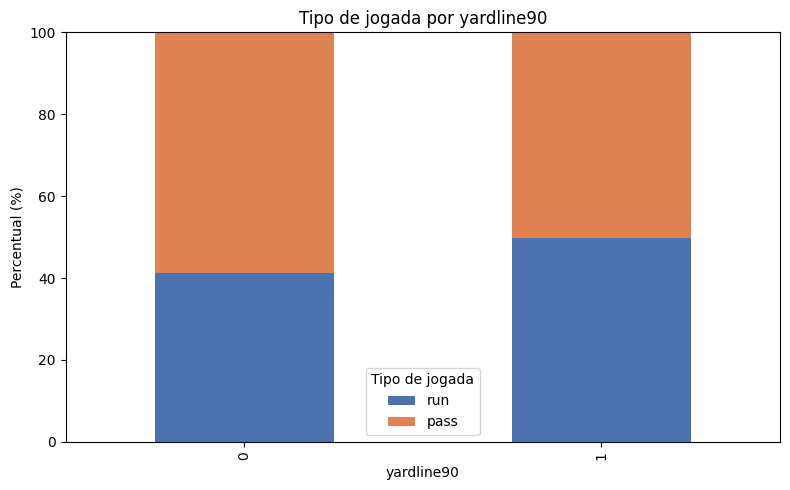

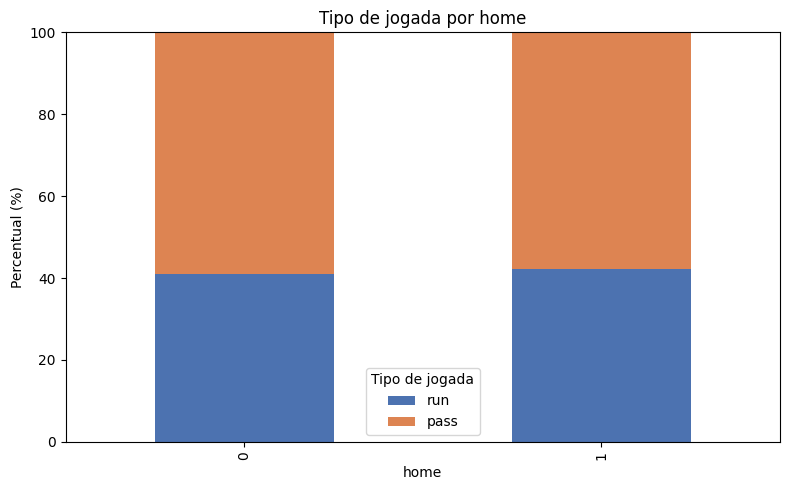

In [9]:
variaveis_barras = [
    "down",
    "qtr",
    "shotgun",
    "nohuddle",
    "goaltogo",
    "yardline90",
    "home"
]

for variavel in variaveis_barras:
    grafico_barra_normalizada(df, variavel)

Função boxplots das variáveis numéricas

In [10]:
def grafico_boxplot(df, variavel):
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=variavel,
        order=CLASSES
    )

    plt.title(f"{variavel} por tipo de jogada")
    plt.xlabel("Tipo de jogada")
    plt.ylabel(variavel)
    plt.tight_layout()
    plt.show()

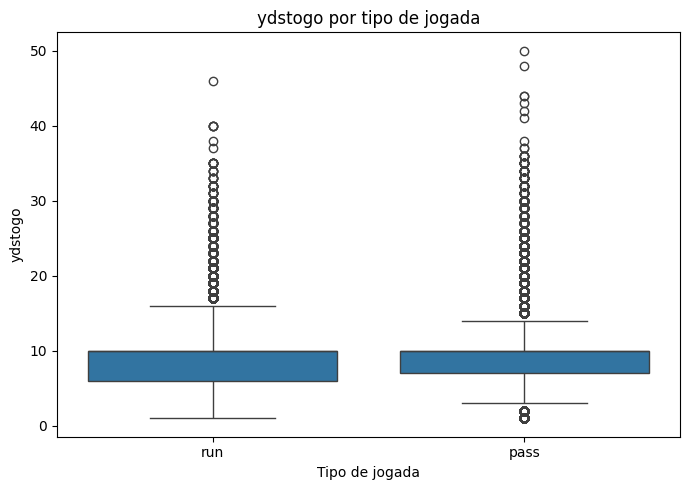

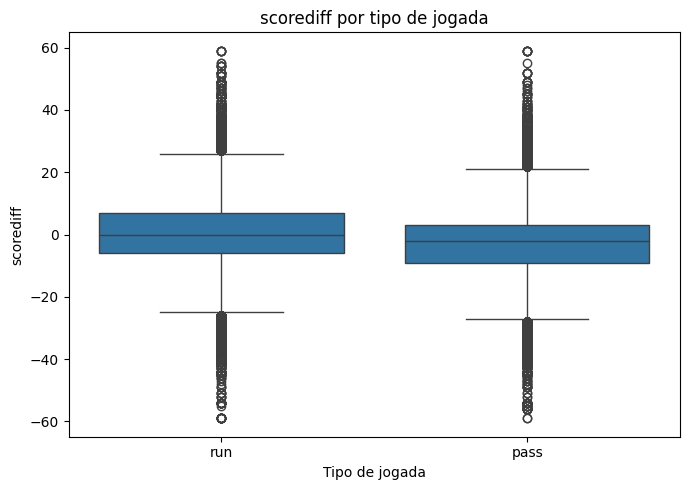

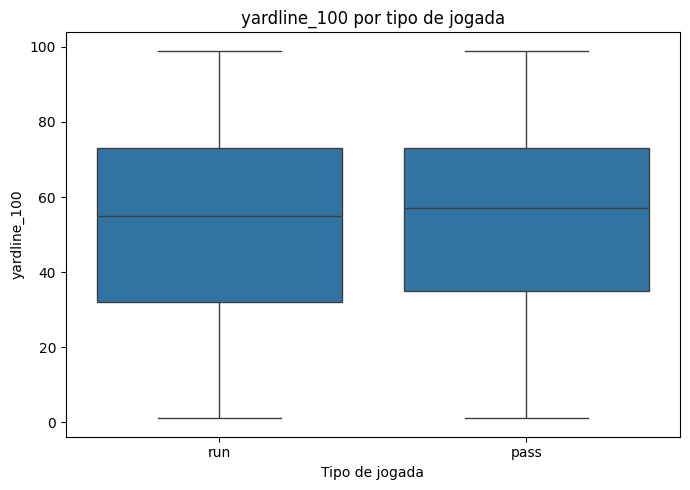

In [11]:
grafico_boxplot(df, "ydstogo")
grafico_boxplot(df, "scorediff")
grafico_boxplot(df, "yardline_100")

HEATMAP

Criar faixas de distância

In [12]:
df["faixa_ydstogo"] = pd.cut(
    df["ydstogo"],
    bins=[0, 2, 5, 9, np.inf],
    labels=["1-2", "3-5", "6-9", "10+"],
    include_lowest=True
)
df["is_pass"] = (df[TARGET] == "pass").astype(int)
heatmap_data = pd.pivot_table(
    df,
    index="down",
    columns="faixa_ydstogo",
    values="is_pass",
    aggfunc="mean",
    observed=False
).mul(100)

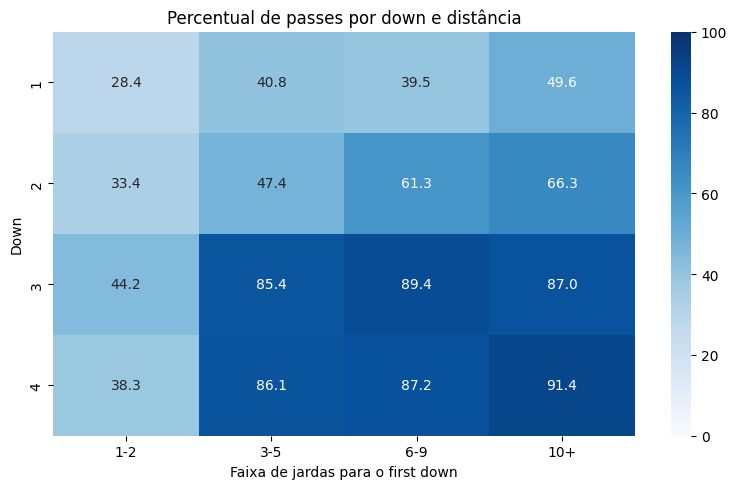

In [13]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Percentual de passes por down e distância")
plt.xlabel("Faixa de jardas para o first down")
plt.ylabel("Down")
plt.tight_layout()
plt.show()


In [14]:
contagens_heatmap = pd.crosstab(
    df["down"],
    df["faixa_ydstogo"]
)

print(contagens_heatmap)

faixa_ydstogo    1-2    3-5    6-9     10+
down                                      
1               2091   3222   3191  132584
2              10542  20040  34895   40685
3              12708  16100  19007   18905
4               2321    989    619     792


Taxa de passe por equipe

In [15]:
contagem_times = df["posteam"].value_counts()

print(contagem_times)

posteam
NE     10515
NO     10446
PHI    10333
HOU    10315
DET    10300
BAL    10259
DEN    10238
ATL    10147
IND    10110
NYJ    10077
JAX    10022
LAC    10008
GB      9980
PIT     9975
CAR     9927
CIN     9894
DAL     9891
NYG     9870
BUF     9834
MIN     9818
KC      9817
WAS     9816
ARI     9812
OAK     9803
CLE     9794
SEA     9776
TB      9769
MIA     9697
LA      9696
SF      9635
CHI     9620
TEN     9497
Name: count, dtype: int64


In [16]:
times_principais = contagem_times.head(MAX_CATEGORIAS).index

df_times = df[df["posteam"].isin(times_principais)].copy()

taxa_passe_time = (
    df_times
    .assign(is_pass=df_times[TARGET].eq("pass"))
    .groupby("posteam")["is_pass"]
    .agg(["mean", "count"])
    .assign(percentual_pass=lambda tabela: tabela["mean"] * 100)
    .sort_values("percentual_pass")
)

print(taxa_passe_time)

             mean  count  percentual_pass
posteam                                  
NYJ      0.537263  10077        53.726307
HOU      0.559767  10315        55.976733
BAL      0.583293  10259        58.329272
DEN      0.584098  10238        58.409846
NE       0.585449  10515        58.544936
JAX      0.587108  10022        58.710836
LAC      0.588129  10008        58.812950
PHI      0.591503  10333        59.150295
ATL      0.611117  10147        61.111659
NO       0.616504  10446        61.650392
IND      0.616617  10110        61.661721
DET      0.634466  10300        63.446602


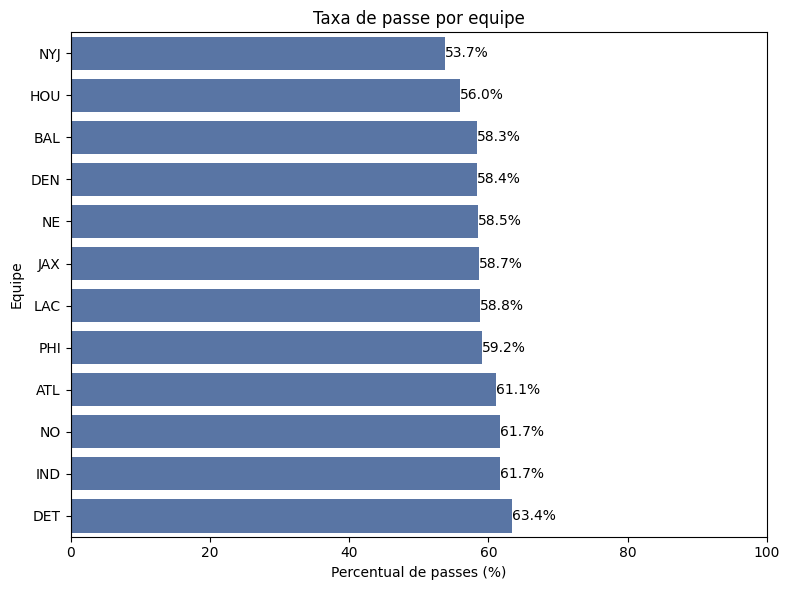

In [17]:
plt.figure(figsize=(8, 6))

ax = sns.barplot(
    data=taxa_passe_time.reset_index(),
    x="percentual_pass",
    y="posteam",
    color="#4C72B0"
)

plt.title("Taxa de passe por equipe")
plt.xlabel("Percentual de passes (%)")
plt.ylabel("Equipe")
plt.xlim(0, 100)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()

Pairplot

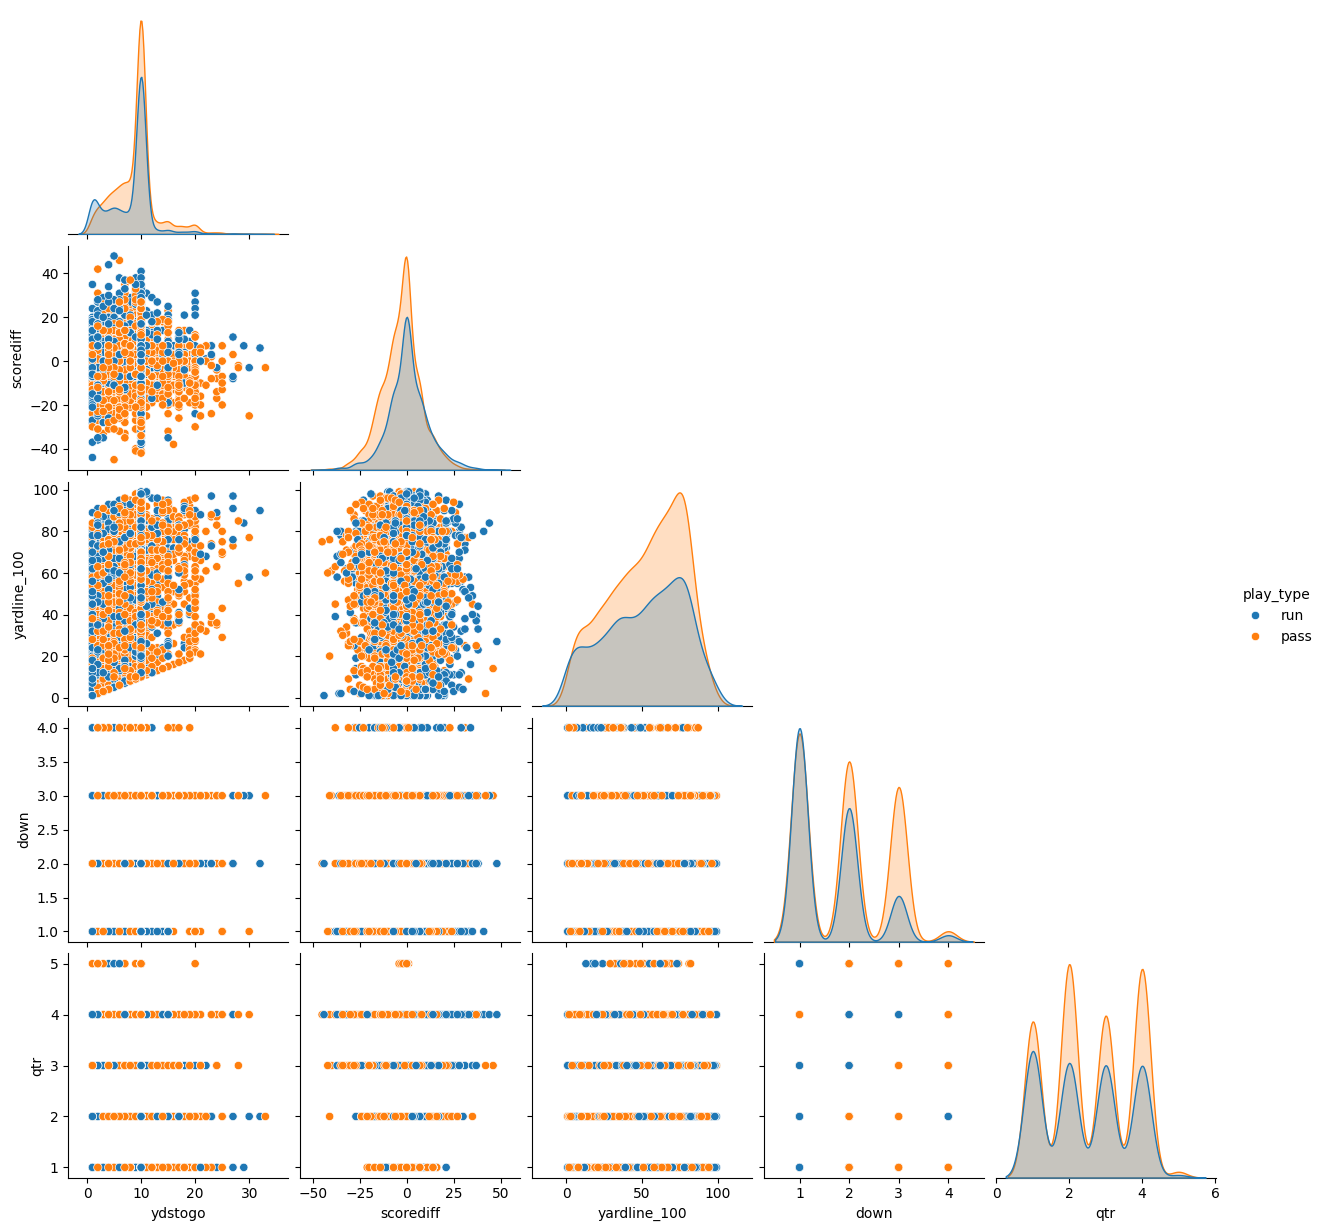

In [18]:
NUMERICAS = [
    "ydstogo",
    "scorediff",
    "yardline_100"
]

CATEGORICAS_ORDINAIS = [
    "down",
    "qtr"
]

CATEGORICAS_BINARIAS = [
    "home",
    "shotgun",
    "nohuddle",
    "goaltogo",
    "yardline90"
]

CATEGORICAS_NOMINAIS = [
    "posteam"
]

colunas_numericas = NUMERICAS + CATEGORICAS_ORDINAIS

df_pairplot = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

sns.pairplot(
    data=df_pairplot,
    vars=colunas_numericas,
    hue=TARGET,
    hue_order=CLASSES,
    corner=True
)

plt.show()

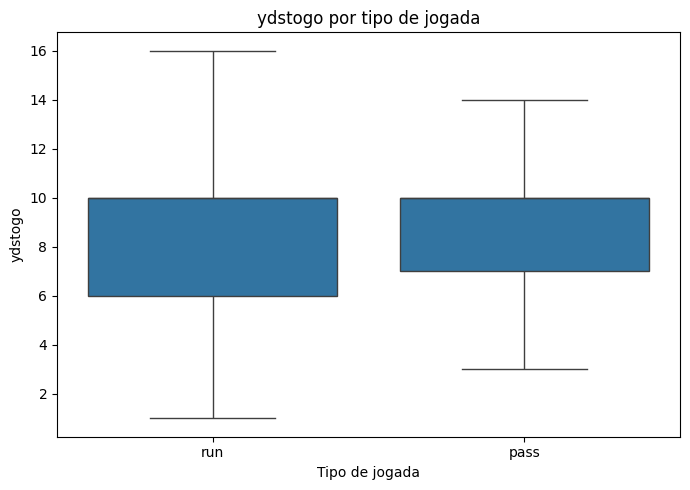

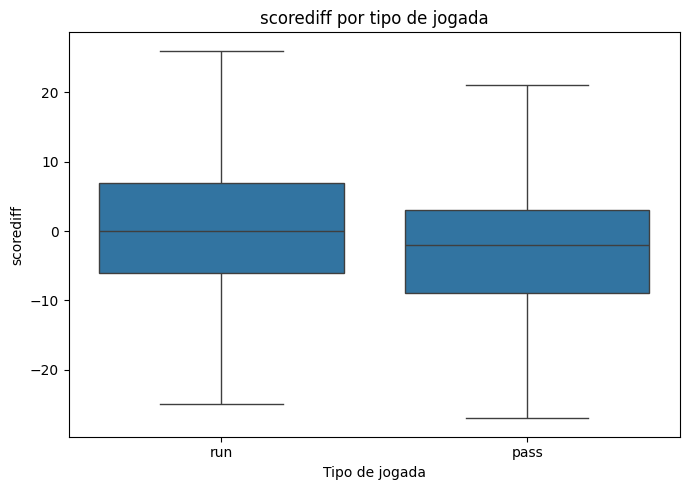

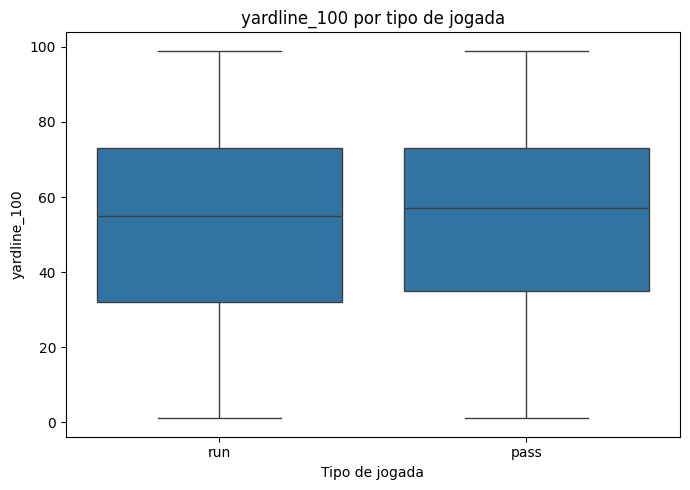

In [21]:
def grafico_boxplot(df, variavel):
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=variavel,
        order=CLASSES,
        showfliers=False
    )

    plt.title(f"{variavel} por tipo de jogada")
    plt.xlabel("Tipo de jogada")
    plt.ylabel(variavel)
    plt.tight_layout()
    plt.show()

grafico_boxplot(df, "ydstogo")
grafico_boxplot(df, "scorediff")
grafico_boxplot(df, "yardline_100")

Original: 318691
Sem outliers: 289124


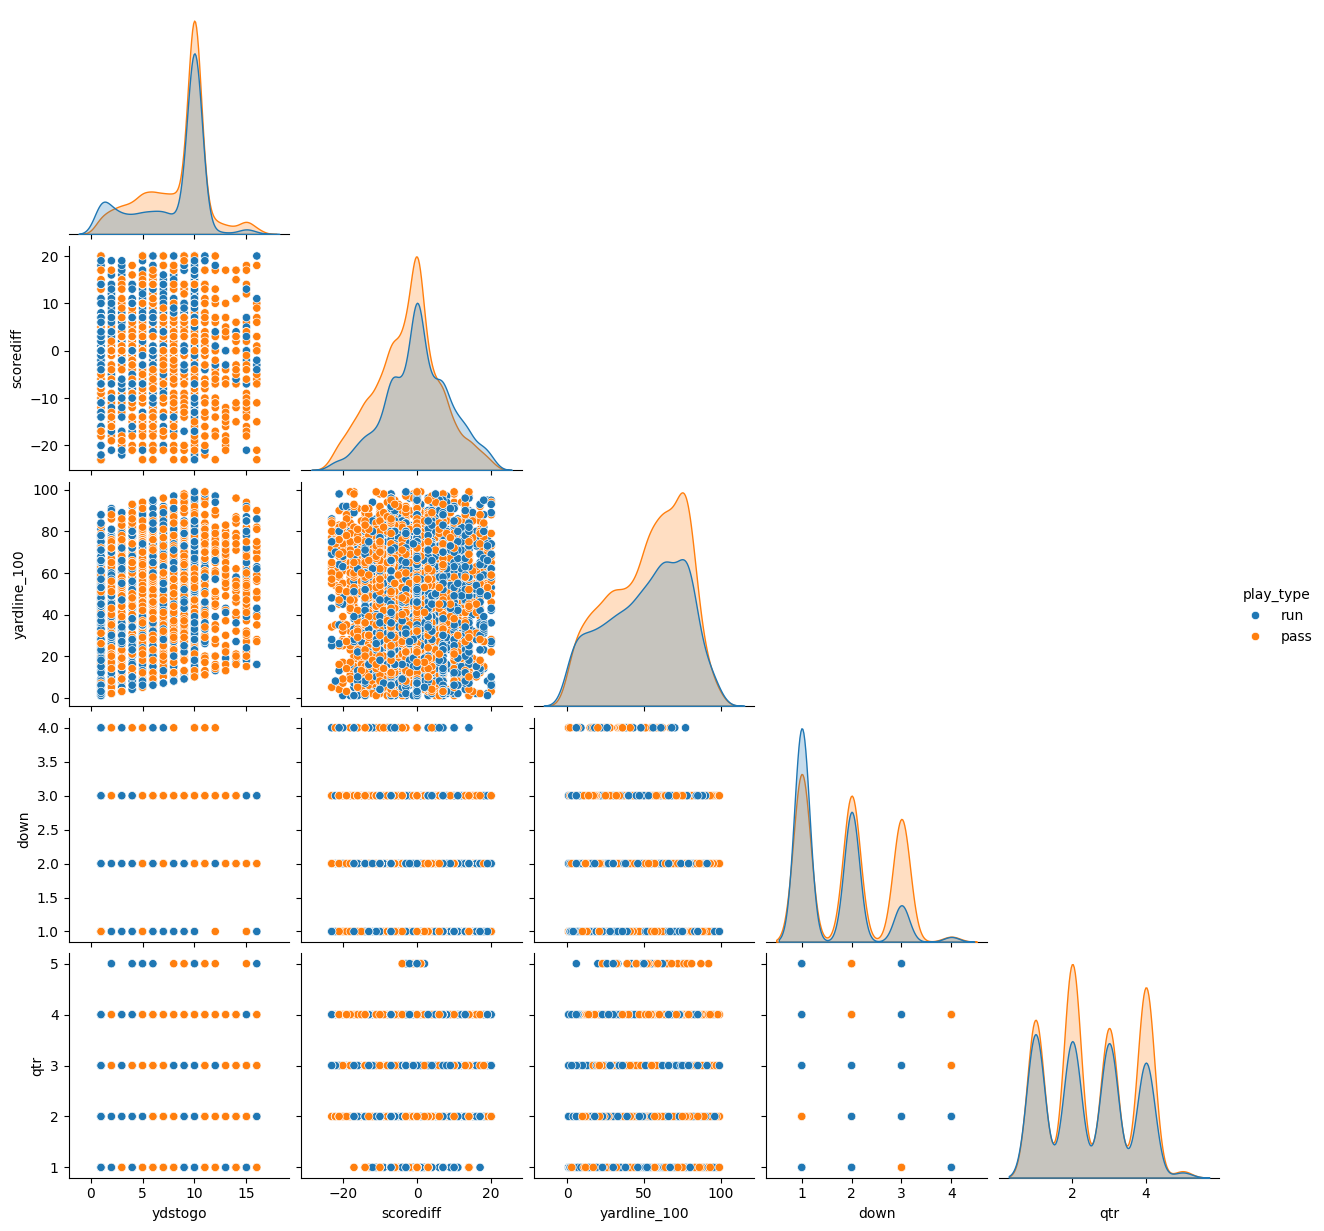

In [22]:
df_sem_outliers = df.copy()

for coluna in NUMERICAS:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    df_sem_outliers = df_sem_outliers[
        df_sem_outliers[coluna].between(
            limite_inferior, limite_superior
        )
    ]

print("Original:", len(df))
print("Sem outliers:", len(df_sem_outliers))


df_pairplot = df_sem_outliers.sample(
    n=min(5000, len(df_sem_outliers)),
    random_state=42
)

sns.pairplot(
    data=df_pairplot,
    vars=colunas_numericas,
    hue=TARGET,
    hue_order=CLASSES,
    corner=True
)

plt.show()